[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/09_rag.ipynb)

*Deep Learning & LLMs · Notebook 9 of 10*

# RAG & Retrieval

Answering from your own documents: chunking, TF-IDF and BM25, vector search, approximate indexes, fusion, MMR, re-ranking, citations and measuring retrieval with recall, MRR and nDCG.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** RAG is an open-book exam: first find the right pages, then answer from them.

**What interviewers really test here:** Chunking, hybrid search, re-ranking, and measuring retrieval separately from the answer.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why RAG exists *(Basics)*
- [ ] 2. Chunking: splitting documents well *(Core)*
- [ ] 3. Keyword search: from TF-IDF to BM25 *(Core)*
- [ ] 4. Vector search *(Core)*
- [ ] 5. Approximate search at scale *(Core)*
- [ ] 6. Hybrid search and re-ranking *(Core)*
- [ ] 7. Diversity and removing repeats *(Core)*
- [ ] 8. Assembling the prompt *(Core)*
- [ ] 9. Measuring retrieval *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Retrieval methods

| Method | Strength | Weakness |
| --- | --- | --- |
| BM25 | exact terms, codes, names | misses synonyms |
| Vector search | meaning, paraphrases | can miss exact identifiers |
| Hybrid (RRF) | the best of both, usually | two systems to run |
| Re-ranker | accuracy | added latency and cost |

### Settings to test

| Setting | Lower | Higher |
| --- | --- | --- |
| Chunk size | precise, little context | more context, blurrier |
| Overlap | less storage | fewer split facts |
| k | cheap, could miss facts | better recall, more tokens |
| nprobe | fast | better recall |
| MMR λ | more diverse | more relevant |

### Do you need RAG?

- **Small, stable knowledge:** just put it in the prompt, with prompt caching.
- **Large or changing documents:** RAG.
- **Live data such as orders or stock:** a tool that queries the system directly.
- **Style or format changes:** prompts first, fine-tuning if needed. RAG won't help.

---
# Part 2: Lessons, step by step

## Lesson 1: Why RAG exists

*Level: Basics*

Ask a model about your company's refund policy and it has two problems: it never saw your documents, and it may answer confidently anyway. Pasting all your documents into every prompt is too slow and expensive, and may not even fit.



**Retrieval-augmented generation** looks up only the relevant pieces, and puts those in the prompt:



<table><tr><th>When</th><th>Step</th><th>What happens</th></tr> <tr><td rowspan="2">Ahead of time</td><td>Chunk</td><td>split documents into pieces</td></tr> <tr><td>Index</td><td>store them for fast search</td></tr> <tr><td rowspan="3">Per question</td><td>Retrieve</td><td>find the pieces matching the question</td></tr> <tr><td>Assemble</td><td>put them in a prompt, with instructions</td></tr> <tr><td>Generate</td><td>the model answers from them</td></tr></table>



The demo runs this whole thing, except the final model call, with about ten lines of NumPy. The question "how long do refunds take" finds the refund policy using TF-IDF, and builds the prompt.



**What RAG gives you:** current information without retraining, access to private data, answers that can cite sources, and an easy way to update (just re-index a document).



**What it doesn't:** it's not a guarantee of truth. If retrieval misses the right passage, the model has nothing to work with. **Most bad RAG answers are retrieval failures**, so when debugging, look at what was retrieved first.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def tiny_rag():
    documents = ["Refunds are processed within 5 business days of the return.",
                 "Standard shipping takes 3 to 7 days within the country.",
                 "You can change your password from the account settings page."]
    question = "how long do refunds take"
    split = [d.lower().replace(".", "").split() for d in documents]
    words = question.split()
    tf = np.array([[d.count(w) / len(d) for w in words] for d in split])
    idf = np.log(len(split) / np.maximum((tf > 0).sum(axis=0), 1))
    scores = tf @ idf
    print("scores:", scores.round(3))
    best = documents[int(scores.argmax())]
    print(f"[1] {best}\n\nQuestion: {question}\nAnswer using only the source. Cite it like [1].")


tiny_rag()

scores: [0.11 0.   0.  ]
[1] Refunds are processed within 5 business days of the return.

Question: how long do refunds take
Answer using only the source. Cite it like [1].


## Lesson 2: Chunking: splitting documents well

*Level: Core*

You retrieve chunks rather than whole documents, so chunk boundaries directly affect quality.



| Too small | Too large |
| --- | --- |
| loses context: "It costs \$5." What does? | the embedding blurs many topics, and costs more tokens |



**Fixed size:** a, b, c, d, e, f, g with size 3 gives abc, def, g. It's simple, but "The fee is / \$5" can be split in half across two chunks, and then neither chunk answers the question.



**Overlap** repeats the end of each chunk at the start of the next. With size 4 and overlap 2, a to h gives abcd, cdef, efgh. Each new chunk moves on by 4 − 2 = 2. The fact that spanned a boundary is now whole in some chunk. The price is more chunks to store: with overlap of half the size, nearly double.



**Respect structure** where possible. Sentence-aware splitting of "One here. Two is here! Is three? Yes." with a 20-character limit gives:



- "One here."
- "Two is here!"
- "Is three? Yes."



Good documents give more clues: headings, paragraphs, table rows, and functions in code. Add a title or section name to each chunk so it stands on its own.



There's no universal best size. Treat size and overlap as settings to test with the metrics at the end of this topic, on your own questions.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 3: Keyword search: from TF-IDF to BM25

*Level: Core*

Keyword search is still excellent, particularly for exact terms: product codes, error messages, names.



**TF-IDF** has a weakness: a word used 100 times scores 100 times higher than one used once. But a page that mentions "refund" 100 times isn't 100 times more about refunds.



**BM25** fixes that with two changes, and it's the usual default:



**score = Σ idf · tf·(k₁ + 1) / (tf + k₁·(1 − b + b·len/avg))**



- **Saturation (k₁ = 1.5):** repeats help less and less. See the chart.
- **Length normalisation (b = 0.75):** long documents contain more words by chance, so they're marked down.



**By hand.** Query "market", on a document of 5 words where it appears once. There are 4 documents, with average length 5.75, and 1 contains the word.



1. idf = ln((4 − 1 + 0.5) / (1 + 0.5) + 1) = ln(3.333) = 1.2040
2. Length part = 1.5 · (0.25 + 0.75 · 5 / 5.75) = 1.3533
3. tf part = 1 · 2.5 / (1 + 1.3533) = 1.0623
4. Score = 1.2040 × 1.0623 = **1.279**



The weakness of keywords is synonyms. "How do I get my money back?" contains no word in "refund policy". That's what vector search is for.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

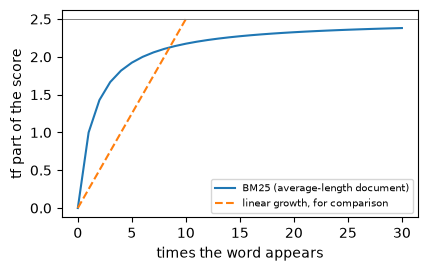

In [3]:
def bm25_saturation():
    tf = np.arange(0, 31)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(tf, tf * 2.5 / (tf + 1.5), label="BM25 (average-length document)")
    ax.plot(tf[:11], tf[:11] * 0.25, label="linear growth, for comparison", linestyle="--")
    ax.axhline(2.5, color="gray", linewidth=0.7)
    ax.set_xlabel("times the word appears")
    ax.set_ylabel("tf part of the score")
    ax.legend(fontsize=7)


bm25_saturation()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 4: Vector search

*Level: Core*

An **embedding model** turns text into a vector so that similar meanings get nearby vectors, even with no shared words. To search, embed the question and find the closest stored vectors.



**By hand** with query (1, 0.2), whose length is 1.0198:



| Vector | Dot | Length | Cosine |
| --- | --- | --- | --- |
| (1, 0) | 1 | 1 | **0.9806** |
| (1, 1) | 1.2 | 1.4142 | **0.8321** |
| (0, 1) | 0.2 | 1 | 0.1961 |



The top 2 are the first and third items in the index.



**Use the same model** for documents and questions, or the vectors aren't comparable. Changing model means re-embedding everything.



**Filter on metadata.** Similarity doesn't know about permissions, dates or teams. Among {a: hr 0.9, b: eng 0.7, c: eng 0.8}, an engineering user gets c, not the higher-scoring a. **For access control, filter in the retrieval layer**, so a user can't get text they're not allowed to read. Never rely on a prompt asking the model not to reveal it.



Brute-force search is simple and exact, and it's a matrix multiplication. It's fine for tens of thousands of chunks. Don't add a vector database until you need one.

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 5: Approximate search at scale

*Level: Core*

With a billion vectors, comparing against all of them per question is too slow. **Approximate nearest-neighbour** indexes trade a little accuracy for a lot of speed.



**IVF (inverted file)** is the easiest to understand:



1. Cluster the vectors, for instance with k-means.
2. Store each vector in the list for its nearest centre.
3. For a query, find the closest `nprobe` centres, and search only their lists.



**By hand.** Vectors: 0: (0, 0), 1: (0, 1), 2: (10, 10), 3: (10, 11), 4: (5, 6). Centres (0, 0) and (10, 10). Query (4.5, 5).



- Vector 4 is at distance 6.40 from (10, 10), and 7.81 from (0, 0), so it's in the second list: {2, 3, 4}. The first list is {0, 1}.
- The query is nearer the first centre (6.73 vs 7.43).
- **nprobe = 1:** searches {0, 1}, and returns vector 1, after 2 comparisons. **Wrong!** Vector 4 is the true nearest.
- **nprobe = 2:** searches everything, and returns 4, after 5 comparisons.



That's the trade-off exactly: a query near a cluster's edge may have its true neighbour in the next cell. Raising `nprobe` buys accuracy with time.



The chart measures this on 5,000 clustered vectors, checked against exact search. Comparing against just 2.6% of them found the true nearest 93% of the time, and 6% found it every time in this run. Other methods exist, with HNSW (a layered graph) being a popular choice. Real data may be less neatly clustered than this synthetic set, so measure recall on your own vectors.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

nprobe: [1, 2, 3, 5, 10]
recall: [0.93 1.   1.   1.   1.  ]
share of data searched: [0.026 0.06  0.093 0.155 0.281]


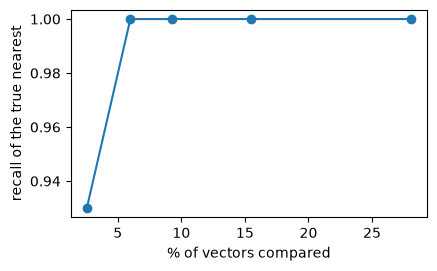

In [4]:
def ivf_tradeoff():
    rng = np.random.default_rng(0)
    n, dim, clusters = 5000, 32, 50
    centres = rng.normal(size=(clusters, dim)) * 3
    data = centres[rng.integers(0, clusters, n)] + rng.normal(size=(n, dim))
    queries = centres[rng.integers(0, clusters, 100)] + rng.normal(size=(100, dim))
    found = data[rng.choice(n, clusters, replace=False)]
    for _ in range(5):
        owner = ((data[:, None] - found) ** 2).sum(axis=2).argmin(axis=1)
        found = np.array([data[owner == k].mean(axis=0) if (owner == k).any() else found[k] for k in range(clusters)])
    truth = [((data - q) ** 2).sum(axis=1).argmin() for q in queries]
    probes, recall, share = [1, 2, 3, 5, 10], [], []
    for nprobe in probes:
        hits, searched = 0, 0
        for q, answer in zip(queries, truth):
            lists = np.argsort(((found - q) ** 2).sum(axis=1))[:nprobe]
            members = np.flatnonzero(np.isin(owner, lists))
            searched += len(members)
            hits += members[((data[members] - q) ** 2).sum(axis=1).argmin()] == answer
        recall.append(hits / len(queries))
        share.append(searched / len(queries) / n)
    print("nprobe:", probes)
    print("recall:", np.round(recall, 2))
    print("share of data searched:", np.round(share, 3))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(np.array(share) * 100, recall, "o-")
    ax.set_xlabel("% of vectors compared")
    ax.set_ylabel("recall of the true nearest")


ivf_tradeoff()

**✏️ Your turn:** you now have what you need for [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 6: Hybrid search and re-ranking

*Level: Core*

Keywords and vectors fail in different ways, so using both usually beats either alone. But how do you combine them? BM25 scores can be 12 while cosines are at most 1, so adding them is meaningless.



**Reciprocal rank fusion** ignores scores and uses only positions: score = Σ 1 / (60 + rank).



With rankings [a, b, c] and [b, c, d]:



| Id | Calculation | Score |
| --- | --- | --- |
| b | 1/62 + 1/61 | **0.03252** |
| c | 1/63 + 1/62 | **0.03200** |
| a | 1/61 | 0.01639 |
| d | 1/63 | 0.01587 |



Note that a was first in one list, but b and c win because both lists agree on them. The 60 keeps a single first place from dominating.



**Re-ranking** adds a second stage. First-stage search is fast but rough, so fetch say 50 candidates, then re-score with a slower, more accurate model, such as a cross-encoder or an LLM, that reads the question and text together. Keep the top few. For candidates a, b, c, d scoring 0.1, 0.9, 0.4, 0.7, the top 2 are b and d.



| Stage | Candidates | Speed | Accuracy |
| --- | --- | --- | --- |
| Hybrid retrieval | millions → 50 | fast | decent |
| Re-ranker | 50 → 5 | slow | good |
| LLM answer | 5 → 1 answer | slowest | uses all context |

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 7: Diversity and removing repeats

*Level: Core*

Top-k has a quiet flaw: it may return five near-identical passages. You pay for all of them, and learn just one fact.



**Maximal marginal relevance** picks items one at a time, balancing relevance against similarity to what's already chosen:



**score = λ·relevance − (1 − λ)·(highest similarity to anything chosen)**



Relevance is 0.9, 0.85, 0.5. Items 0 and 1 are near-duplicates (similarity 0.95), and item 2 is different (0.1). With λ = 0.5:



- **Round 1:** nothing is chosen yet, so pick the most relevant: item 0.
- **Round 2, item 1:** 0.5·0.85 − 0.5·0.95 = **−0.05**.
- **Round 2, item 2:** 0.5·0.5 − 0.5·0.1 = **+0.20**. Picked.



Result: [0, 2]. With λ = 1, it's plain relevance, giving [0, 1].



**Remove near-duplicates** using Jaccard overlap: shared words ÷ all distinct words. "the cat sat" and "the cat sat down" share 3 of 4 words: 0.75. At a 0.7 limit, the second is dropped. "stocks fell today" shares none and stays.



Overlapping chunks cause exactly this kind of repeat, so it's a good idea to dedupe after using overlap.

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 8: Assembling the prompt

*Level: Core*

The last mile matters too. A good RAG prompt gives numbered sources, the question, and clear rules:



```python
[1] Paris is in France.
[2] It has the Louvre.

Question: Where is Paris?
Answer using only the sources. Cite them like [1].
```



**Fit the budget.** With sizes 500, 800, 300, 400 and a budget of 1,000: keep 500; 800 doesn't fit; keep 300 (800 in total); 400 doesn't fit. Result: chunks 0 and 2.



**Allow "I don't know".** If the best score is weak, don't force an answer. With threshold 0.5, scores 0.8, 0.4, 0.6 keep two chunks. A single score of 0.3 returns "no\_answer", which beats a confident invention. Tell the model to say so as well, if the sources don't contain the answer. Thresholds differ per embedding model, so set them from your own data.



**Check citations in code.** Models can cite sources that don't exist. For "Paris is in France [1]. It is big [2][1]. Also [7]." with 2 sources: valid are [1, 2], and **invalid is [7]**. A valid number doesn't prove that the source says it, though. That takes evaluation or human checks.



**Retrieved text is untrusted**: a web page or document could contain instructions aimed at your model. Keep it in tags, and don't give the model powerful tools in the same task without checks.

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q5](#q5), [Q7](#q7), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 9: Measuring retrieval

*Level: Advanced*

Measure retrieval separately from the answer. You need a test set of questions with known relevant chunks, ideally from real user questions.



Retrieved: a, b, c, d. Relevant: b, d, e.



| Metric | Question | k = 2 | k = 4 |
| --- | --- | --- | --- |
| Recall@k | How much of what matters did we find? | 1/3 = 0.333 | 2/3 = 0.667 |
| Precision@k | How much of what we returned matters? | 1/2 = 0.5 | 2/4 = 0.5 |



For RAG, **recall usually matters most**. If a passage isn't retrieved, the model can't use it; a few extras are less harmful.



**MRR** rewards a high first hit. Three queries, with the first relevant result at rank 1, rank 3 and nowhere: (1 + 1/3 + 0) / 3 = **0.4444**.



**nDCG** handles graded relevance (2 = perfect, 1 = useful, 0 = no), and rewards putting the best first, by dividing each relevance by log₂(position + 1). For relevances 0, 1, 2:



- DCG = 0/1 + 1/1.585 + 2/2 = 1.631
- Ideal order 2, 1, 0: 2/1 + 1/1.585 + 0 = 2.631
- nDCG = 1.631 / 2.631 = **0.620**



**A debugging order for a bad answer:**



1. Is the fact in your documents at all?
2. Was it split badly during chunking?
3. Was it retrieved? Check recall.
4. Did it survive re-ranking and the budget?
5. Did the model use it correctly?



Change one thing at a time, and re-measure.

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q9](#q9), [Q16](#q16), [Q20](#q20). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [5]:
import re


<a id="q1"></a>
### Q1. Fixed-Size Chunks

🟢 Warm-up · *The simplest splitter*

Split tokens into chunks of the given size. The last may be shorter.

**Examples**

- `tokens = ['a', 'b', 'c', 'd', 'e', 'f', 'g'], size = 3` → `[['a', 'b', 'c'], ['d', 'e', 'f'], ['g']]`

In [ ]:
def fixed_chunks(tokens, size):
    """
    Split tokens into chunks of the given size. The last may be shorter.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fixed_chunks, [
    ((['a', 'b', 'c', 'd', 'e', 'f', 'g'], 3), [['a', 'b', 'c'], ['d', 'e', 'f'], ['g']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Slices in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension with a step.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Slices in a loop.

```python
def fixed_chunks(tokens, size):
    out, i = [], 0
    while i < len(tokens):
        out.append(tokens[i:i + size])
        i += size
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension with a step.

```python
def fixed_chunks(tokens, size):
    return [tokens[i:i + size] for i in range(0, len(tokens), size)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Slices in a loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension with a step. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/fixed-size-chunks)

<a id="q2"></a>
### Q2. Chunks With Overlap

🟢 Warm-up · *Don't cut facts in half*

Chunks of the given size, each starting (size − overlap) after the previous. Stop once a chunk reaches the end.

**Examples**

- `tokens = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'], size = 4, overlap = 2` → `[['a', 'b', 'c', 'd'], ['c', 'd', 'e', 'f'], ['e', 'f', 'g', 'h']]`
- `tokens = ['a', 'b', 'c', 'd', 'e'], size = 3, overlap = 1` → `[['a', 'b', 'c'], ['c', 'd', 'e']]`

In [ ]:
def overlap_chunks(tokens, size, overlap):
    """
    Chunks of the given size, each starting (size − overlap) after the previous.
    Stop once a chunk reaches the end.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(overlap_chunks, [
    ((['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h'], 4, 2), [['a', 'b', 'c', 'd'], ['c', 'd', 'e', 'f'], ['e', 'f', 'g', 'h']]),
    ((['a', 'b', 'c', 'd', 'e'], 3, 1), [['a', 'b', 'c'], ['c', 'd', 'e']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop with a break.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Work out how many chunks first.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A while loop with a break.

```python
def overlap_chunks(tokens, size, overlap):
    out, i = [], 0
    while True:
        out.append(tokens[i:i + size])
        if i + size >= len(tokens):
            break
        i += size - overlap
    return out
```

**Cost:** O(n) time, O(n·s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Work out how many chunks first.

```python
def overlap_chunks(tokens, size, overlap):
    step = size - overlap
    n = max(0, math.ceil((len(tokens) - size) / step)) + 1
    return [tokens[i * step:i * step + size] for i in range(n)]
```

**Cost:** O(n) time, O(n·s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop with a break. That costs O(n) time and O(n·s) space."

"I can do better: Work out how many chunks first. That's O(n) time and O(n·s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/chunks-with-overlap)

<a id="q3"></a>
### Q3. Vector Top-k

🟢 Warm-up · *Semantic search*

Return indices of the k vectors with the highest cosine similarity to the query, with scores rounded to 4 decimals.

**Examples**

- `vectors = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], query = [1.0, 0.2], k = 2` → `([0, 2], [0.9806, 0.8321])`

In [ ]:
def vector_top_k(vectors, query, k):
    """
    Return indices of the k vectors with the highest cosine similarity to the
    query, with scores rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(vector_top_k, [
    (([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], [1.0, 0.2], 2), ([0, 2], [0.9806, 0.8321])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute cosine in a loop, then sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Normalise, then a matrix-vector product and `argsort`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute cosine in a loop, then sort.

```python
def vector_top_k(vectors, query, k):
    q_len = math.sqrt(sum(v * v for v in query))
    scored = []
    for i, vec in enumerate(vectors):
        dot = sum(a * b for a, b in zip(vec, query))
        scored.append((-dot / (math.sqrt(sum(a * a for a in vec)) * q_len), i))
    scored.sort()
    return ([i for _, i in scored[:k]], [round(-s, 4) for s, _ in scored[:k]])
```

**Cost:** O(n·d + n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Normalise, then a matrix-vector product and `argsort`.

```python
def vector_top_k(vectors, query, k):
    V, q = np.array(vectors), np.array(query)
    scores = V @ q / (np.linalg.norm(V, axis=1) * np.linalg.norm(q))
    top = np.argsort(-scores)[:k]
    return (top, scores[top].round(4))
```

**Cost:** O(n·d + n log n) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute cosine in a loop, then sort. That costs O(n·d + n log n) time and O(n) space."

"I can do better: Normalise, then a matrix-vector product and `argsort`. That's O(n·d + n log n) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/vector-top-k)

<a id="q4"></a>
### Q4. Re-Rank the Candidates

🟢 Warm-up · *Cheap first, careful second*

Given candidate ids and a re-ranker's scores, return the top k ids by those scores.

**Examples**

- `ids = ['a', 'b', 'c', 'd'], scores = [0.1, 0.9, 0.4, 0.7], k = 2` → `['b', 'd']`

In [ ]:
def rerank(ids, scores, k):
    """
    Given candidate ids and a re-ranker's scores, return the top k ids by those
    scores.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rerank, [
    ((['a', 'b', 'c', 'd'], [0.1, 0.9, 0.4, 0.7], 2), ['b', 'd']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.argsort`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sort pairs.

```python
def rerank(ids, scores, k):
    pairs = sorted(zip(scores, ids), reverse=True)
    return [doc for _, doc in pairs[:k]]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.argsort`.

```python
def rerank(ids, scores, k):
    return [ids[i] for i in np.argsort(scores)[::-1][:k]]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort pairs. That costs O(n log n) time and O(n) space."

"I can do better: `np.argsort`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/re-rank-the-candidates)

<a id="q5"></a>
### Q5. Say When You Don't Know

🟢 Warm-up · *A retrieval threshold*

If the best score is below the threshold, return 'no\_answer'. Otherwise return the ids at or above it, best first.

**Examples**

- `hits = [('a', 0.8), ('b', 0.4), ('c', 0.6)], threshold = 0.5` → `['a', 'c']`
- `hits = [('a', 0.3)], threshold = 0.5` → `'no_answer'`

In [ ]:
def threshold_hits(hits, threshold):
    """
    If the best score is below the threshold, return 'no_answer'. Otherwise
    return the ids at or above it, best first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(threshold_hits, [
    (([('a', 0.8), ('b', 0.4), ('c', 0.6)], 0.5), ['a', 'c']),
    (([('a', 0.3)], 0.5), 'no_answer'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Filter and sort in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Filter and sort in a loop.

```python
def threshold_hits(hits, threshold):
    kept = []
    for doc, score in hits:
        if score >= threshold:
            kept.append((score, doc))
    if not kept:
        return "no_answer"
    kept.sort(reverse=True)
    return [doc for _, doc in kept]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted comprehension.

```python
def threshold_hits(hits, threshold):
    kept = [doc for doc, s in sorted(hits, key=lambda h: -h[1]) if s >= threshold]
    return kept or "no_answer"
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Filter and sort in a loop. That costs O(n log n) time and O(n) space."

"I can do better: A sorted comprehension. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/say-when-you-dont-know)

<a id="q6"></a>
### Q6. Fit Chunks Into the Budget

🟢 Warm-up · *Best first, until full*

Go through chunk sizes in rank order, keeping each that still fits (later smaller chunks may still fit). Return kept indices.

**Examples**

- `sizes = [500, 800, 300, 400], budget = 1000` → `[0, 2]`

In [ ]:
def fit_chunks(sizes, budget):
    """
    Go through chunk sizes in rank order, keeping each that still fits (later
    smaller chunks may still fit). Return kept indices.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fit_chunks, [
    (([500, 800, 300, 400], 1000), [0, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with a running total.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

It's already simple; a loop is the right tool.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with a running total.

```python
def fit_chunks(sizes, budget):
    kept, used = [], 0
    for i in range(len(sizes)):
        if used + sizes[i] <= budget:
            kept.append(i)
            used = used + sizes[i]
    return kept
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** It's already simple; a loop is the right tool.

```python
def fit_chunks(sizes, budget):
    kept = []
    for i, size in enumerate(sizes):
        if size <= budget:
            kept.append(i)
            budget -= size
    return kept
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with a running total. That costs O(n) time and O(n) space."

"I can do better: It's already simple; a loop is the right tool. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/fit-chunks-into-the-budget)

<a id="q7"></a>
### Q7. Build the Prompt With Sources

🟢 Warm-up · *Make answers checkable*

Return lines '[1] text', '[2] text'… then a blank line, then 'Question: …', then the instruction 'Answer using only the sources. Cite them like [1].'

**Examples**

- `chunks = ['Paris is in France.', 'It has the Louvre.'], question = 'Where is Paris?'` → `'[1] Paris is in France.\n[2] It has the Louvre.\n\nQuestion: Where is Paris?\nAnswer using only the sources. Cite them like [1].'`

In [ ]:
def rag_prompt(chunks, question):
    """
    Return lines '[1] text', '[2] text'… then a blank line, then 'Question: …',
    then the instruction 'Answer using only the sources. Cite them like [1].'
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rag_prompt, [
    ((['Paris is in France.', 'It has the Louvre.'], 'Where is Paris?'), '[1] Paris is in France.\n[2] It has the Louvre.\n\nQuestion: Where is Paris?\nAnswer using only the sources. Cite them like [1].'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Append with a counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`enumerate(..., 1)` and `join`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Append with a counter.

```python
def rag_prompt(chunks, question):
    lines = []
    n = 1
    for c in chunks:
        lines.append("[" + str(n) + "] " + c)
        n += 1
    lines.append("")
    lines.append("Question: " + question)
    lines.append("Answer using only the sources. Cite them like [1].")
    return "\n".join(lines)
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `enumerate(..., 1)` and `join`.

```python
def rag_prompt(chunks, question):
    sources = "\n".join(f"[{i}] {c}" for i, c in enumerate(chunks, 1))
    return f"{sources}\n\nQuestion: {question}\nAnswer using only the sources. Cite them like [1]."
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Append with a counter. That costs O(total) time and O(total) space."

"I can do better: `enumerate(..., 1)` and `join`. That's O(total) time and O(total) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/build-the-prompt-with-sources)

<a id="q8"></a>
### Q8. Recall@k

🟢 Warm-up · *Did we find it?*

Return the fraction of relevant ids in the first k retrieved, rounded to 4 decimals.

**Examples**

- `retrieved = ['a', 'b', 'c', 'd'], relevant = ['b', 'd', 'e'], k = 2` → `0.3333`
- `retrieved = ['a', 'b', 'c', 'd'], relevant = ['b', 'd', 'e'], k = 4` → `0.6667`

In [ ]:
def recall_at_k(retrieved, relevant, k):
    """
    Return the fraction of relevant ids in the first k retrieved, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(recall_at_k, [
    ((['a', 'b', 'c', 'd'], ['b', 'd', 'e'], 2), 0.3333),
    ((['a', 'b', 'c', 'd'], ['b', 'd', 'e'], 4), 0.6667),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set intersection.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count in a loop.

```python
def recall_at_k(retrieved, relevant, k):
    found = 0
    for r in relevant:
        if r in retrieved[:k]:
            found += 1
    return round(found / len(relevant), 4)
```

**Cost:** O(k·r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set intersection.

```python
def recall_at_k(retrieved, relevant, k):
    return round(len(set(retrieved[:k]) & set(relevant)) / len(relevant), 4)
```

**Cost:** O(k + r) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop. That costs O(k·r) time and O(1) space."

"I can do better: Set intersection. That's O(k + r) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/recall-k)

<a id="q9"></a>
### Q9. Precision@k

🟢 Warm-up · *How much is noise?*

Return the fraction of the first k retrieved that are relevant, rounded to 4 decimals.

**Examples**

- `retrieved = ['a', 'b', 'c', 'd'], relevant = ['b', 'd', 'e'], k = 2` → `0.5`
- `retrieved = ['a', 'b', 'c', 'd'], relevant = ['b', 'd', 'e'], k = 4` → `0.5`

In [ ]:
def precision_at_k(retrieved, relevant, k):
    """
    Return the fraction of the first k retrieved that are relevant, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(precision_at_k, [
    ((['a', 'b', 'c', 'd'], ['b', 'd', 'e'], 2), 0.5),
    ((['a', 'b', 'c', 'd'], ['b', 'd', 'e'], 4), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set intersection.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count in a loop.

```python
def precision_at_k(retrieved, relevant, k):
    found = 0
    for r in retrieved[:k]:
        if r in relevant:
            found += 1
    return round(found / k, 4)
```

**Cost:** O(k·r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set intersection.

```python
def precision_at_k(retrieved, relevant, k):
    return round(len(set(retrieved[:k]) & set(relevant)) / k, 4)
```

**Cost:** O(k + r) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop. That costs O(k·r) time and O(1) space."

"I can do better: Set intersection. That's O(k + r) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/precision-k)

<a id="q10"></a>
### Q10. Sentence-Aware Chunks

🟡 Interview standard · *Keep sentences whole*

Split text into sentences, then greedily join them up to max\_chars (joined with a space). A sentence is never split.

**Examples**

- `text = 'One here. Two is here! Is three? Yes.', max_chars = 20` → `['One here.', 'Two is here!', 'Is three? Yes.']`

In [ ]:
def sentence_chunks(text, max_chars):
    """
    Split text into sentences, then greedily join them up to max_chars (joined
    with a space). A sentence is never split.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sentence_chunks, [
    (('One here. Two is here! Is three? Yes.', 20), ['One here.', 'Two is here!', 'Is three? Yes.']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan for ending punctuation, then fill chunks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A regular expression to split, then the same greedy fill.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Scan for ending punctuation, then fill chunks.

```python
def sentence_chunks(text, max_chars):
    sentences, current = [], ""
    for ch in text:
        current += ch
        if ch in ".!?":
            sentences.append(current.strip())
            current = ""
    if current.strip():
        sentences.append(current.strip())
    chunks, chunk = [], ""
    for s in sentences:
        if chunk and len(chunk) + 1 + len(s) > max_chars:
            chunks.append(chunk)
            chunk = s
        else:
            chunk = chunk + " " + s if chunk else s
    if chunk:
        chunks.append(chunk)
    return chunks
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A regular expression to split, then the same greedy fill.

```python
def sentence_chunks(text, max_chars):
    chunks = []
    for s in re.split(r"(?<=[.!?])\s+", text.strip()):
        if chunks and len(chunks[-1]) + 1 + len(s) <= max_chars:
            chunks[-1] += " " + s
        else:
            chunks.append(s)
    return chunks
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan for ending punctuation, then fill chunks. That costs O(n) time and O(n) space."

"I can do better: A regular expression to split, then the same greedy fill. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/sentence-aware-chunks)

<a id="q11"></a>
### Q11. Rank by TF-IDF

🟡 Interview standard · *Keyword search*

Score each doc as Σ over query words of (count / doc length) × ln(N / df), skipping words in no document. Return doc indices best first, keeping those with a score above 0.

**Examples**

- `docs = [['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], query = ['cats', 'dogs']` → `[1, 3]`
- `docs = [['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], query = ['market', 'the']` → `[2, 0, 1]`

In [ ]:
def tfidf_rank(docs, query):
    """
    Score each doc as Σ over query words of (count / doc length) × ln(N / df),
    skipping words in no document. Return doc indices best first, keeping those
    with a score above 0.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tfidf_rank, [
    (([['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], ['cats', 'dogs']), [1, 3]),
    (([['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], ['market', 'the']), [2, 0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops per word and document.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Count words once in a table, then use array operations.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops per word and document.

```python
def tfidf_rank(docs, query):
    scored = []
    for i, d in enumerate(docs):
        score = 0.0
        for w in query:
            df = sum(1 for doc in docs if w in doc)
            if df:
                score += d.count(w) / len(d) * math.log(len(docs) / df)
        if score > 0:
            scored.append((-score, i))
    return [i for _, i in sorted(scored)]
```

**Cost:** O(q·total) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Count words once in a table, then use array operations.

```python
def tfidf_rank(docs, query):
    tf = np.array([[d.count(w) / len(d) for w in query] for d in docs])
    df = (tf > 0).sum(axis=0)
    idf = np.log(len(docs) / np.maximum(df, 1))
    scores = tf @ idf
    order = sorted(range(len(docs)), key=lambda i: (-scores[i], i))
    return [i for i in order if scores[i] > 0]
```

**Cost:** O(total + q·n) time, O(n·V) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops per word and document. That costs O(q·total) time and O(n) space."

"I can do better: Count words once in a table, then use array operations. That's O(total + q·n) time and O(n·V) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/rank-by-tf-idf)

<a id="q12"></a>
### Q12. Filter, Then Search

🟡 Interview standard · *Metadata matters*

Only consider items whose metadata has the given team. Return the id with the highest score, or None.

**Examples**

- `items = [{'id': 'a', 'team': 'hr', 'score': 0.9}, {'id': 'b', 'team': 'eng', 'score': 0.7}, {'id': 'c', 'team': 'eng', 'score': 0.8}], team = 'eng'` → `'c'`
- `items = [{'id': 'a', 'team': 'hr', 'score': 0.9}], team = 'eng'` → `None`

In [ ]:
def filtered_best(items, team):
    """
    Only consider items whose metadata has the given team. Return the id with
    the highest score, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(filtered_best, [
    (([{'id': 'a', 'team': 'hr', 'score': 0.9}, {'id': 'b', 'team': 'eng', 'score': 0.7}, {'id': 'c', 'team': 'eng', 'score': 0.8}], 'eng'), 'c'),
    (([{'id': 'a', 'team': 'hr', 'score': 0.9}], 'eng'), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop tracking the best.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`max` with a generator and a default.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop tracking the best.

```python
def filtered_best(items, team):
    best, best_score = None, -1
    for item in items:
        if item["team"] == team and item["score"] > best_score:
            best, best_score = item["id"], item["score"]
    return best
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `max` with a generator and a default.

```python
def filtered_best(items, team):
    match = max((x for x in items if x["team"] == team), key=lambda x: x["score"], default=None)
    return match["id"] if match else None
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop tracking the best. That costs O(n) time and O(1) space."

"I can do better: `max` with a generator and a default. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/filter-then-search)

<a id="q13"></a>
### Q13. Reciprocal Rank Fusion

🟡 Interview standard · *Combine two rankings*

Score each id as Σ 1 / (k + rank), with ranks from 1 and k = 60. Return ids best first. RRF needs no comparable scores, just ranks.

**Examples**

- `rankings = [['a', 'b', 'c'], ['b', 'c', 'd']]` → `['b', 'c', 'a', 'd']`

In [ ]:
def rrf(rankings):
    """
    Score each id as Σ 1 / (k + rank), with ranks from 1 and k = 60. Return ids
    best first. RRF needs no comparable scores, just ranks.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rrf, [
    (([['a', 'b', 'c'], ['b', 'c', 'd']],), ['b', 'c', 'a', 'd']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary of scores.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`defaultdict` with `sorted`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A dictionary of scores.

```python
def rrf(rankings):
    scores = {}
    for ranking in rankings:
        for pos in range(len(ranking)):
            doc = ranking[pos]
            scores[doc] = scores.get(doc, 0) + 1 / (60 + pos + 1)
    return sorted(scores, key=lambda d: -scores[d])
```

**Cost:** O(total log total) time, O(ids) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `defaultdict` with `sorted`.

```python
def rrf(rankings):
    from collections import defaultdict
    scores = defaultdict(float)
    for ranking in rankings:
        for rank, doc in enumerate(ranking, 1):
            scores[doc] += 1 / (60 + rank)
    return sorted(scores, key=scores.get, reverse=True)
```

**Cost:** O(total log total) time, O(ids) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary of scores. That costs O(total log total) time and O(ids) space."

"I can do better: `defaultdict` with `sorted`. That's O(total log total) time and O(ids) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/reciprocal-rank-fusion)

<a id="q14"></a>
### Q14. Remove Near-Duplicates

🟡 Interview standard · *Don't pay for repeats*

Keep a chunk only if its Jaccard word overlap with every kept chunk is below the limit. Return kept indices.

**Examples**

- `chunks = ['the cat sat', 'the cat sat down', 'stocks fell today'], limit = 0.7` → `[0, 2]`

In [ ]:
def dedupe(chunks, limit):
    """
    Keep a chunk only if its Jaccard word overlap with every kept chunk is below
    the limit. Return kept indices.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dedupe, [
    ((['the cat sat', 'the cat sat down', 'stocks fell today'], 0.7), [0, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare to each kept chunk.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Pre-compute sets, and use `all`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compare to each kept chunk.

```python
def dedupe(chunks, limit):
    kept = []
    for i, text in enumerate(chunks):
        words = text.split()
        duplicate = False
        for j in kept:
            other = chunks[j].split()
            shared = len([w for w in set(words) if w in other])
            union = len(set(words + other))
            if shared / union >= limit:
                duplicate = True
                break
        if not duplicate:
            kept.append(i)
    return kept
```

**Cost:** O(n²·w) time, O(n·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Pre-compute sets, and use `all`.

```python
def dedupe(chunks, limit):
    sets = [set(c.split()) for c in chunks]
    kept = []
    for i, s in enumerate(sets):
        if all(len(s & sets[j]) / len(s | sets[j]) < limit for j in kept):
            kept.append(i)
    return kept
```

**Cost:** O(n²·w) time, O(n·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare to each kept chunk. That costs O(n²·w) time and O(n·w) space."

"I can do better: Pre-compute sets, and use `all`. That's O(n²·w) time and O(n·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/remove-near-duplicates)

<a id="q15"></a>
### Q15. Check the Citations

🟡 Interview standard · *Catch invented sources*

Find every [n] in the answer. Return (sorted valid numbers, sorted invalid numbers), given n\_sources sources.

**Examples**

- `answer = 'Paris is in France [1]. It is big [2][1]. Also [7].', n_sources = 2` → `([1, 2], [7])`

In [ ]:
def check_citations(answer, n_sources):
    """
    Find every [n] in the answer. Return (sorted valid numbers, sorted invalid
    numbers), given n_sources sources.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(check_citations, [
    (('Paris is in France [1]. It is big [2][1]. Also [7].', 2), ([1, 2], [7])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan for brackets by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`re.findall(r'\[(\d+)\]', …)` and sets.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Scan for brackets by hand.

```python
def check_citations(answer, n_sources):
    valid, invalid = [], []
    i = 0
    while i < len(answer):
        if answer[i] == "[":
            j = answer.find("]", i)
            if j != -1 and answer[i + 1:j].isdigit():
                n = int(answer[i + 1:j])
                target = valid if 1 <= n <= n_sources else invalid
                if n not in target:
                    target.append(n)
        i += 1
    return (sorted(valid), sorted(invalid))
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `re.findall(r'\[(\d+)\]', …)` and sets.

```python
def check_citations(answer, n_sources):
    found = {int(n) for n in re.findall(r"\[(\d+)\]", answer)}
    return (sorted(n for n in found if 1 <= n <= n_sources), sorted(n for n in found if not 1 <= n <= n_sources))
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan for brackets by hand. That costs O(n) time and O(c) space."

"I can do better: `re.findall(r'\[(\d+)\]', …)` and sets. That's O(n) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/check-the-citations)

<a id="q16"></a>
### Q16. Mean Reciprocal Rank

🟡 Interview standard · *How high is the first hit?*

For each query, score 1 / (rank of first relevant result), or 0 if none. Return the mean, rounded to 4 decimals.

**Examples**

- `results = [(['a', 'b', 'c'], ['a']), (['a', 'b', 'c'], ['c']), (['a', 'b'], ['z'])]` → `0.4444`

In [ ]:
def mrr(results):
    """
    For each query, score 1 / (rank of first relevant result), or 0 if none.
    Return the mean, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mrr, [
    (([(['a', 'b', 'c'], ['a']), (['a', 'b', 'c'], ['c']), (['a', 'b'], ['z'])],), 0.4444),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`next` with a generator, sets for relevance.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops.

```python
def mrr(results):
    total = 0.0
    for retrieved, relevant in results:
        for pos in range(len(retrieved)):
            if retrieved[pos] in relevant:
                total += 1 / (pos + 1)
                break
    return round(total / len(results), 4)
```

**Cost:** O(q·k·r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `next` with a generator, sets for relevance.

```python
def mrr(results):
    scores = [next((1 / rank for rank, d in enumerate(ret, 1) if d in set(rel)), 0) for ret, rel in results]
    return round(float(np.mean(scores)), 4)
```

**Cost:** O(q·k) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops. That costs O(q·k·r) time and O(1) space."

"I can do better: `next` with a generator, sets for relevance. That's O(q·k) time and O(r) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `results = [(['a', 'b', 'c'], ['a']), (['a', 'b', 'c'], ['c']), (['a', 'b'], ['z'])]`

1. GeneratorExit raised: 
2. GeneratorExit raised: 
3. mrr() returns 0.4444

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/mean-reciprocal-rank)

<a id="q17"></a>
### Q17. BM25 Score

🔴 Stretch · *The standard for keyword search*

Score doc i: Σ idf·tf·(k1 + 1) / (tf + k1·(1 − b + b·len/avg\_len)), with idf = ln((N − df + 0.5)/(df + 0.5) + 1), k1 = 1.5, b = 0.75. Round to 4 decimals.

**Examples**

- `docs = [['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], query = ['market'], i = 2` → `1.279`
- `docs = [['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], query = ['cats', 'dogs'], i = 3` → `1.3597`

In [ ]:
def bm25(docs, query, i):
    """
    Score doc i: Σ idf·tf·(k1 + 1) / (tf + k1·(1 − b + b·len/avg_len)), with idf
    = ln((N − df + 0.5)/(df + 0.5) + 1), k1 = 1.5, b = 0.75. Round to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bm25, [
    (([['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], ['market'], 2), 1.279),
    (([['the', 'cat', 'sat', 'on', 'the', 'mat'], ['dogs', 'chase', 'cats', 'in', 'the', 'park'], ['the', 'stock', 'market', 'fell', 'today'], ['cats', 'and', 'dogs', 'are', 'popular', 'pets']], ['cats', 'dogs'], 3), 1.3597),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over query words and documents.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Array of lengths; set membership for df.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops over query words and documents.

```python
def bm25(docs, query, i):
    k1, b = 1.5, 0.75
    N = len(docs)
    avg = sum(len(d) for d in docs) / N
    score = 0.0
    for w in query:
        df = sum(1 for d in docs if w in d)
        idf = math.log((N - df + 0.5) / (df + 0.5) + 1)
        tf = docs[i].count(w)
        score += idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * len(docs[i]) / avg))
    return round(score, 4)
```

**Cost:** O(q·total) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Array of lengths; set membership for df.

```python
def bm25(docs, query, i):
    k1, b = 1.5, 0.75
    lengths = np.array([len(d) for d in docs])
    tf = np.array([docs[i].count(w) for w in query])
    df = np.array([sum(w in d for d in docs) for w in query])
    idf = np.log((len(docs) - df + 0.5) / (df + 0.5) + 1)
    return round(float((idf * tf * (k1 + 1) / (tf + k1 * (1 - b + b * lengths[i] / lengths.mean()))).sum()), 4)
```

**Cost:** O(q·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over query words and documents. That costs O(q·total) time and O(1) space."

"I can do better: Array of lengths; set membership for df. That's O(q·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/bm25-score)

<a id="q18"></a>
### Q18. An Approximate Index

🔴 Stretch · *Search only part of the data*

IVF: each vector belongs to its nearest centroid. Find the nprobe centroids nearest to the query, then search only their vectors. Return (best index by distance, distances computed to vectors).

**Examples**

- `vectors = [[0.0, 0.0], [0.0, 1.0], [10.0, 10.0], [10.0, 11.0], [5.0, 6.0]], centroids = [[0.0, 0.0], [10.0, 10.0]], query = [4.5, 5.0], nprobe = 1` → `(1, 2)`
- `vectors = [[0.0, 0.0], [0.0, 1.0], [10.0, 10.0], [10.0, 11.0], [5.0, 6.0]], centroids = [[0.0, 0.0], [10.0, 10.0]], query = [4.5, 5.0], nprobe = 2` → `(4, 5)`

In [ ]:
def ivf_search(vectors, centroids, query, nprobe):
    """
    IVF: each vector belongs to its nearest centroid. Find the nprobe centroids
    nearest to the query, then search only their vectors. Return (best index by
    distance, distances computed to vectors).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ivf_search, [
    (([[0.0, 0.0], [0.0, 1.0], [10.0, 10.0], [10.0, 11.0], [5.0, 6.0]], [[0.0, 0.0], [10.0, 10.0]], [4.5, 5.0], 1), (1, 2)),
    (([[0.0, 0.0], [0.0, 1.0], [10.0, 10.0], [10.0, 11.0], [5.0, 6.0]], [[0.0, 0.0], [10.0, 10.0]], [4.5, 5.0], 2), (4, 5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for assigning and for searching.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Distance matrices with broadcasting.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for assigning and for searching.

```python
def ivf_search(vectors, centroids, query, nprobe):
    def dist(a, b):
        return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))
    lists = [[] for _ in centroids]
    for i, v in enumerate(vectors):
        nearest = min(range(len(centroids)), key=lambda c: dist(v, centroids[c]))
        lists[nearest].append(i)
    probes = sorted(range(len(centroids)), key=lambda c: dist(query, centroids[c]))[:nprobe]
    best, best_d, count = None, float("inf"), 0
    for c in probes:
        for i in lists[c]:
            count += 1
            d = dist(vectors[i], query)
            if d < best_d:
                best, best_d = i, d
    return (best, count)
```

**Cost:** O(n·c) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Distance matrices with broadcasting.

```python
def ivf_search(vectors, centroids, query, nprobe):
    V, C, q = np.array(vectors), np.array(centroids), np.array(query)
    owner = np.linalg.norm(V[:, None] - C, axis=2).argmin(axis=1)
    probes = np.argsort(np.linalg.norm(C - q, axis=1))[:nprobe]
    members = np.flatnonzero(np.isin(owner, probes))
    return (int(members[np.linalg.norm(V[members] - q, axis=1).argmin()]), len(members))
```

**Cost:** O(n·c) time, O(n·c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for assigning and for searching. That costs O(n·c) time and O(n) space."

"I can do better: Distance matrices with broadcasting. That's O(n·c) time and O(n·c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/an-approximate-index)

<a id="q19"></a>
### Q19. Maximal Marginal Relevance

🔴 Stretch · *Relevant but not repetitive*

Pick k items. Each round, maximise λ·relevance − (1 − λ)·(highest similarity to anything chosen). Return the picks in order.

**Examples**

- `rel = [0.9, 0.85, 0.5], sim = [[1.0, 0.95, 0.1], [0.95, 1.0, 0.1], [0.1, 0.1, 1.0]], k = 2, lam = 0.5` → `[0, 2]`
- `rel = [0.9, 0.85, 0.5], sim = [[1.0, 0.95, 0.1], [0.95, 1.0, 0.1], [0.1, 0.1, 1.0]], k = 2, lam = 1.0` → `[0, 1]`

In [ ]:
def mmr(rel, sim, k, lam):
    """
    Pick k items. Each round, maximise λ·relevance − (1 − λ)·(highest similarity
    to anything chosen). Return the picks in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mmr, [
    (([0.9, 0.85, 0.5], [[1.0, 0.95, 0.1], [0.95, 1.0, 0.1], [0.1, 0.1, 1.0]], 2, 0.5), [0, 2]),
    (([0.9, 0.85, 0.5], [[1.0, 0.95, 0.1], [0.95, 1.0, 0.1], [0.1, 0.1, 1.0]], 2, 1.0), [0, 1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops each round.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Maintain the highest similarity in an array, updating each round.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops each round.

```python
def mmr(rel, sim, k, lam):
    chosen = []
    while len(chosen) < k:
        best, best_score = None, -float("inf")
        for i in range(len(rel)):
            if i in chosen:
                continue
            penalty = max((sim[i][j] for j in chosen), default=0)
            score = lam * rel[i] - (1 - lam) * penalty
            if score > best_score:
                best, best_score = i, score
        chosen.append(best)
    return chosen
```

**Cost:** O(k²·n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Maintain the highest similarity in an array, updating each round.

```python
def mmr(rel, sim, k, lam):
    rel, sim = np.array(rel), np.array(sim)
    penalty = np.zeros(len(rel))
    available = np.ones(len(rel), dtype=bool)
    chosen = []
    for _ in range(k):
        score = lam * rel - (1 - lam) * penalty
        score[~available] = -np.inf
        best = int(score.argmax())
        chosen.append(best)
        available[best] = False
        penalty = np.maximum(penalty, sim[best])
    return chosen
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops each round. That costs O(k²·n) time and O(k) space."

"I can do better: Maintain the highest similarity in an array, updating each round. That's O(k·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/maximal-marginal-relevance)

<a id="q20"></a>
### Q20. nDCG@k

🔴 Stretch · *Graded relevance, order matters*

DCG = Σ relᵢ / log₂(i + 1), with i from 1. Return DCG@k ÷ the DCG@k of the ideal order, rounded to 4 decimals.

**Examples**

- `rel = [3, 2, 3, 0, 1, 2], k = 6` → `0.9608`
- `rel = [2, 1, 0], k = 3` → `1.0`
- `rel = [0, 1, 2], k = 3` → `0.6199`

In [ ]:
def ndcg(rel, k):
    """
    DCG = Σ relᵢ / log₂(i + 1), with i from 1. Return DCG@k ÷ the DCG@k of the
    ideal order, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ndcg, [
    (([3, 2, 3, 0, 1, 2], 6), 0.9608),
    (([2, 1, 0], 3), 1.0),
    (([0, 1, 2], 3), 0.6199),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for both.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A discount array shared by both.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for both.

```python
def ndcg(rel, k):
    def dcg(values):
        total = 0.0
        for i, v in enumerate(values[:k]):
            total += v / math.log2(i + 2)
        return total
    return round(dcg(rel) / dcg(sorted(rel, reverse=True)), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A discount array shared by both.

```python
def ndcg(rel, k):
    r = np.array(rel, dtype=float)
    discount = 1 / np.log2(np.arange(2, len(r) + 2))
    return round(float((r[:k] * discount[:k]).sum() / (np.sort(r)[::-1][:k] * discount[:k]).sum()), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for both. That costs O(n log n) time and O(n) space."

"I can do better: A discount array shared by both. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/rag/ndcg-k)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why chunk at all?</b></summary>

Embedding a whole document blurs its topics, and passing it entire costs many tokens. Chunks let you retrieve just the relevant part.

</details>

<details>
<summary><b>2. BM25 or embeddings?</b></summary>

Often both. Keywords catch exact terms, embeddings catch paraphrases. Reciprocal rank fusion combines them without comparable scores.

</details>

<details>
<summary><b>3. What does a re-ranker do?</b></summary>

It re-scores a shortlist with a slower, more accurate model that reads the query and passage together.

</details>

<details>
<summary><b>4. Which metric matters most?</b></summary>

Usually recall@k, since the model can't use what wasn't retrieved. Then use MRR or nDCG to judge ordering.

</details>

<details>
<summary><b>5. How should permissions work in RAG?</b></summary>

Filter in the retrieval layer, so unauthorised text never reaches the prompt. Don't rely on instructions to the model.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why RAG exists
- [ ] I can explain: Chunking: splitting documents well
- [ ] I can explain: Keyword search: from TF-IDF to BM25
- [ ] I can explain: Vector search
- [ ] I can explain: Approximate search at scale
- [ ] I can explain: Hybrid search and re-ranking
- [ ] I can explain: Diversity and removing repeats
- [ ] I can explain: Assembling the prompt
- [ ] I can explain: Measuring retrieval

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Mean Reciprocal Rank
- [ ] [Q17](#q17) BM25 Score
- [ ] [Q18](#q18) An Approximate Index
- [ ] [Q19](#q19) Maximal Marginal Relevance
- [ ] [Q20](#q20) nDCG@k

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.